Conditional Agents with Conditional Edges

In [1]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END

In [2]:
class AgentState (TypedDict):
    number1 : int 
    number2 : int 
    final1 : int

    number3 : int
    number4 : int
    final2 : int 
    
    operation1 : str
    operation2 : str

In [3]:
def adder1(state : AgentState) -> AgentState:
    """This node adds Two Numbers"""
    state['final1'] = state['number1'] + state['number2']
    return state

def subtractor1(state:AgentState) -> AgentState:
    """This node subtracts the 2 numbers"""
    state['final1'] = state['number1'] - state['number2']
    return state

def decision_node1( state : AgentState) -> AgentState:
    """This node will select the next phase"""

    if state['operation1'] =="+":
        return "addition_operation"
    elif state['operation1'] == "-":
        return "subtraction operation"


def adder2( state: AgentState)-> AgentState:
    """This node adds Two Numbers"""
    state['final2'] = state['number3'] + state['number4']
    return state

def subtractor2(state : AgentState) -> AgentState:
    """This node subtracts the 2 numbers"""
    state['final2'] = state['number3'] - state['number4']
    return state

def decision_node2( state : AgentState) -> AgentState:
    """This node will select the next phase"""

    if state['operation2'] =="+":
        return "addition_operation2"
    elif state['operation2'] == "-":
        return "subtraction_operation2"


In [4]:
graph = StateGraph(AgentState)

graph.add_node("router1", lambda state: state) # basic pass through function - your initial state and final state are the same, no change 
graph.add_node("adder1" , adder1)
graph.add_node("subtractor1", subtractor1)

graph.add_node("router2", lambda state: state) # basic pass through function - your initial state and final state are the same, no change 
graph.add_node("adder2" , adder2)
graph.add_node("subtractor2", subtractor2)



graph.add_edge(START, "router1")
graph.add_conditional_edges(
    "router1",
    decision_node1,
    {
        #Edge : Node
        "addition_operation": "adder1",
        "subtraction_operation": "adder2"
    }

)

graph.add_edge("adder1", "router2")
graph.add_edge("adder2", "router2")

graph.add_conditional_edges(
    "router2",
    decision_node2,
    {
        # Edge: Node
        "addition_operation": "adder2",
        "subtractor1_operation": "subtractor2"
    }
)

graph.add_edge("adder2", END)
graph.add_edge("subtractor2", END)

def decision_node1(state: AgentState):
    if state["operation1"] == "+":
        return "addition_operation"
    elif state["operation1"] == "-":
        return "subtraction_operation"
    return END

def decision_node2(state: AgentState):
    if state["operation2"] == "+":
        return "addition_operation2"
    elif state["operation2"] == "-":
        return "subtraction_operation2"
    return END

graph = StateGraph(AgentState)

graph.add_node("router1", lambda state: state)
graph.add_node("adder1", adder1)
graph.add_node("subtractor1", subtractor1)

graph.add_node("router2", lambda state: state)
graph.add_node("adder2", adder2)
graph.add_node("subtractor2", subtractor2)

graph.add_edge(START, "router1")

graph.add_conditional_edges(
    "router1",
    decision_node1,
    {
        "addition_operation": "adder1",
        "subtraction_operation": "subtractor1",
    },
)

graph.add_edge("adder1", "router2")
graph.add_edge("subtractor1", "router2")

graph.add_conditional_edges(
    "router2",
    decision_node2,
    {
        "addition_operation2": "adder2",
        "subtraction_operation2": "subtractor2",
    },
)

graph.add_edge("adder2", END)
graph.add_edge("subtractor2", END)

app = graph.compile()


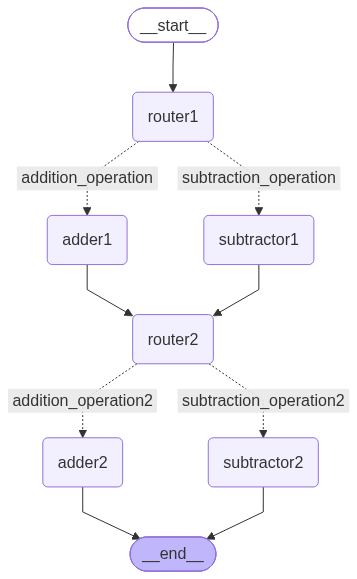

In [5]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [6]:
initial_state = {
    "number1": 10,
    "number2": 5,
    "final1": 0,
    "number3": 7,
    "number4": 2,
    "final2": 0,
    "operation1": "-",
    "operation2": "+",
}
print(app.invoke(initial_state))


{'number1': 10, 'number2': 5, 'final1': 5, 'number3': 7, 'number4': 2, 'final2': 9, 'operation1': '-', 'operation2': '+'}
